# N1. Learned reduced-order modeling of a single scattering wavefunction

[Daniel: Introduce the real Woods–Saxon single-channel case and distinguish training from held-out predictions.]

In [1]:
# Large binaries are loaded from ../CleanCode relative to this notebook, not duplicated here.
import os, sys, tempfile
from pathlib import Path
NOTEBOOK_DIR = Path.cwd().resolve()
if not (NOTEBOOK_DIR / "N1_simple_case.ipynb").is_file():
    raise RuntimeError("Run this notebook from its notebooks directory.")
ROOT = NOTEBOOK_DIR.parent
SOURCE_ROOT = (ROOT / "../CleanCode").resolve()
sys.path.insert(0, str(ROOT))
sys.dont_write_bytecode = True
_matplotlib_config = tempfile.TemporaryDirectory(prefix="lrom-mpl-")
os.environ["MPLCONFIGDIR"] = _matplotlib_config.name

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import lrom
import pandas as pd
from lrom import BasisConfig, MaxVol, ScatteringLROM, ScatteringProblem, get_runtime
from lrom.physics import real_woods_saxon, two_body_kinematics
from lrom.reduced import latin_hypercube
from lrom.diagnostics import absolute_l2, relative_l2
from IPython.display import Math, display

assert Path(lrom.__file__).resolve().parent == ROOT / "lrom"
assert SOURCE_ROOT.is_dir()
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 85, "savefig.dpi": 150})
COLORS = {"LS": "#2457E6", "LROM": "#E6AB02"}
PARAMETER_CMAP = LinearSegmentedColormap.from_list(
    "parameter", ["#2446A8", "#7776D4", "#C66EC5", "#F15A9D"]
)
ERROR_FLOOR = 1.0e-12
SEED = 1204
BASIS_SIZE = 4
reduced_mass, com_energy, relativistic_k = two_body_kinematics(
    40, 20, 1, 0, 14.1,
    target_binding_energy=342.052184,  # AME2020 binding energy for 40Ca
)
problem = ScatteringProblem(
    potential="real_woods_saxon", target_a=40, target_z=20,
    lab_energy=14.1, l_max=0, mesh_points=800,
    target_binding_energy=342.052184,
)
system = problem.system()
s_mesh = system.s_mesh
radius = system.radius
radial_error_mask = radius >= 0.5
omega0 = np.array([46.7238, 4.0538, 0.6718])
BACKEND = "cpu"
PRECISION = "double"
runtime = get_runtime(BACKEND, PRECISION)

def samples_from_rows(rows):
    '''Convert ordered (Vv, Rv, av) rows to the package's named inputs.'''
    return [
        {"Vv": float(row[0]), "Rv": float(row[1]), "av": float(row[2]),
         "E": 14.1, "A": 40, "Z": 20}
        for row in np.asarray(rows)
    ]

reference_data = problem.generate_training_data([problem.reference_sample])
phi0 = reference_data.reference_wavefunctions[(0, 0.0)]
potential0 = real_woods_saxon(radius, omega0)

def save_figure(name):
    fig = plt.gcf()
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

print(f"online runtime: {runtime.name} on {runtime.device} ({runtime.precision})")

online runtime: numpy-cpu on CPU (double)


## Mathematical structure

[Daniel: Explain the scaled Schrödinger equation, central-reference representation, centered snapshot SVD, and potential predictors.]

In [2]:
display(Math('\\phi(s;\\boldsymbol\\omega) \\approx \\phi_0(s)\n+ \\sum_{i=1}^{N_\\phi} a_i(\\boldsymbol\\omega)\\,\\psi_i(s),'))
display(Math('\\left[I+\\sum_{j=1}^{N_p}p_j(\\boldsymbol\\omega)M_j\\right]a\n=\\sum_{j=1}^{N_p}p_j(\\boldsymbol\\omega)b_j.'))
display(Math(r"s=kr,\qquad \widetilde U(s)=V(s/k)/E_{\rm cm}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

[Daniel: State the learned implicit reduced equation and distinguish least-squares projection from prediction.]

[Daniel: schematic]

# 1. Variation of the real depth $V_v$

[Daniel: Describe depth training and testing intervals at fixed radius, diffuseness, and energy.]

In [3]:
train_vv = np.tile(omega0, (35, 1))
test_vv = np.tile(omega0, (41, 1))
train_vv[:, 0] = np.linspace(.90 * omega0[0], 1.10 * omega0[0], len(train_vv))
test_vv[:, 0] = np.linspace(.65 * omega0[0], 1.35 * omega0[0], len(test_vv))

train_samples_vv = samples_from_rows(train_vv)
test_samples_vv = samples_from_rows(test_vv)
noncentral_train_vv = ~np.isclose(train_vv[:, 0], omega0[0])
noncentral_test_vv = ~np.isclose(test_vv[:, 0], omega0[0])
training_data_vv = problem.generate_training_data(train_samples_vv)
testing_data_vv = problem.generate_training_data(test_samples_vv)
train_phi_vv = training_data_vv.wavefunctions[(0, 0.0)]
test_phi_vv = testing_data_vv.wavefunctions[(0, 0.0)]
train_potential_vv = training_data_vv.potentials[(0, 0.0)]
test_potential_vv = testing_data_vv.potentials[(0, 0.0)]
train_physical_potential_vv = np.asarray([
    real_woods_saxon(radius, row) for row in train_vv
])

pd.DataFrame({
    "set": ["training", "testing"],
    "cases": [len(train_vv), len(test_vv)],
    "Vv minimum [MeV]": [train_vv[:,0].min(), test_vv[:,0].min()],
    "Vv maximum [MeV]": [train_vv[:,0].max(), test_vv[:,0].max()],
})

,set,cases,Vv minimum [MeV],Vv maximum [MeV]
0,training,35,42.05142,51.39618
1,testing,41,30.37047,63.07713


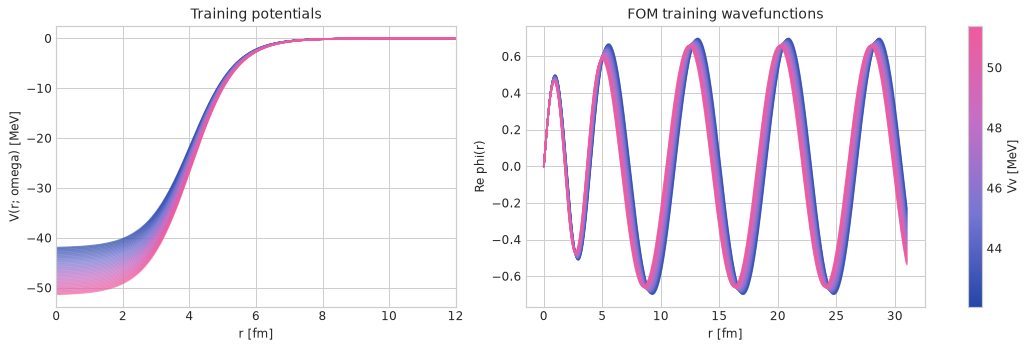

In [4]:
norm = plt.Normalize(train_vv[:, 0].min(), train_vv[:, 0].max())
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for vv, optical, wave in zip(train_vv[:, 0], train_physical_potential_vv, train_phi_vv):
    color = PARAMETER_CMAP(norm(vv))
    axes[0].plot(radius, optical.real, color=color, alpha=.65)
    axes[1].plot(radius, wave.real, color=color, alpha=.65)
axes[0].set(xlim=(0, 12), xlabel="r [fm]", ylabel="V(r; omega) [MeV]", title="Training potentials")
axes[1].set(xlabel="r [fm]", ylabel="Re phi(r)", title="FOM training wavefunctions")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=PARAMETER_CMAP), ax=axes, label="Vv [MeV]")
save_figure("N1_vv_snapshots")

## 1.1 Reduced basis and learned coordinate map

[Daniel: Explain four retained modes, one potential predictor, and the least-squares basis accuracy limit.]

In [5]:
emulator_vv = ScatteringLROM(
    problem, BasisConfig(size=BASIS_SIZE), MaxVol(count=1),
).train(training_data_vv)
model_vv = emulator_vv.channel_models[(0, 0.0)].learned
predictions_train_vv = [emulator_vv.predict(sample) for sample in train_samples_vv]
predictions_test_vv = [emulator_vv.predict(sample) for sample in test_samples_vv]
lrom_train_vv = np.asarray([p.wavefunction((0, 0.0)) for p in predictions_train_vv])
lrom_test_vv = np.asarray([p.wavefunction((0, 0.0)) for p in predictions_test_vv])
lrom_train_coordinates_vv = np.asarray([p.coordinates((0, 0.0)) for p in predictions_train_vv])
lrom_test_coordinates_vv = np.asarray([p.coordinates((0, 0.0)) for p in predictions_test_vv])

ls_train_coordinates_vv = model_vv.basis.project(train_phi_vv)
ls_test_coordinates_vv = model_vv.basis.project(test_phi_vv)
ls_train_vv = model_vv.basis.reconstruct(ls_train_coordinates_vv)
ls_test_vv = model_vv.basis.reconstruct(ls_test_coordinates_vv)

pd.Series({
    "basis size": BASIS_SIZE,
    "predictor count": 1,
    "selected s": model_vv.selected_coordinates[0],
    "selected radius [fm]": model_vv.selected_coordinates[0] / system.wave_number,
    "implicit-fit residual MSE": model_vv.fit_residual,
}, name="Vv-only LROM")

basis size                   4.000000e+00
predictor count              1.000000e+00
selected s                   1.258210e-01
selected radius [fm]         1.552892e-01
implicit-fit residual MSE    1.139689e-15
Name: Vv-only LROM, dtype: float64

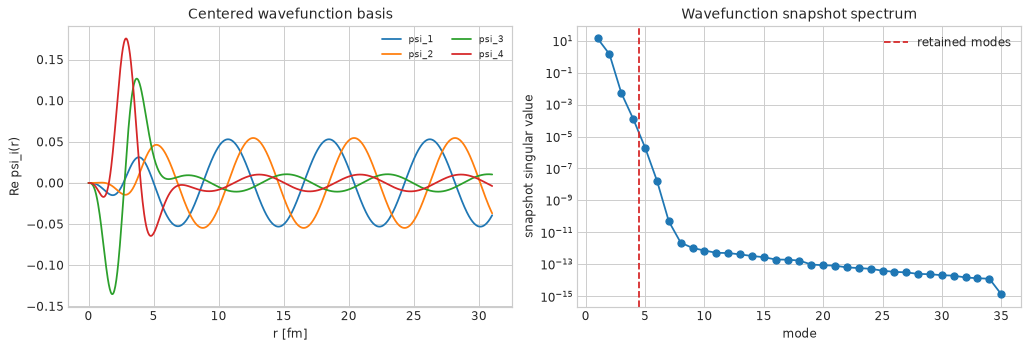

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for index in range(BASIS_SIZE):
    axes[0].plot(radius, model_vv.basis.vectors[:, index].real, label=f"psi_{index+1}")
axes[0].set(xlabel="r [fm]", ylabel="Re psi_i(r)", title="Centered wavefunction basis")
axes[0].legend(ncol=2, fontsize=8)
singular = model_vv.basis.singular_values
axes[1].semilogy(np.arange(1, len(singular)+1), singular, "o-")
axes[1].axvline(BASIS_SIZE + .5, color="C3", ls="--", label="retained modes")
axes[1].set(xlabel="mode", ylabel="snapshot singular value", title="Wavefunction snapshot spectrum")
axes[1].legend()
save_figure("N1_vv_basis")

## 1.3 Reduced coordinates

[Daniel: Compare least-squares and learned reduced coordinates across interpolation and extrapolation intervals.]

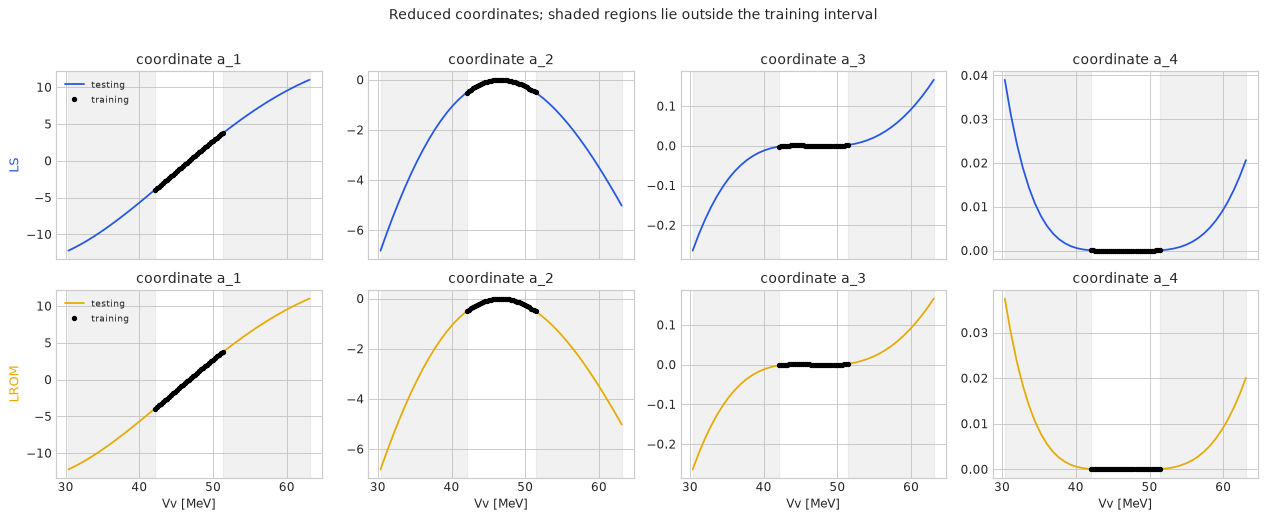

In [7]:
coordinate_rows = [
    ("LS", ls_train_coordinates_vv, ls_test_coordinates_vv, "a", COLORS["LS"]),
    ("LROM", lrom_train_coordinates_vv, lrom_test_coordinates_vv, "a", COLORS["LROM"]),
]
train_min, train_max = train_vv[:,0].min(), train_vv[:,0].max()
fig, axes = plt.subplots(2, BASIS_SIZE, figsize=(15, 6), sharex=True)
for row_index, (name, training, testing, symbol, color) in enumerate(coordinate_rows):
    for column in range(BASIS_SIZE):
        ax = axes[row_index, column]
        ax.plot(test_vv[:,0], testing[:,column].real, color=color, label="testing")
        ax.plot(train_vv[:,0], training[:,column].real, "o", ms=3.5, color="black", label="training")
        ax.axvspan(test_vv[:,0].min(), train_min, color="0.7", alpha=.18)
        ax.axvspan(train_max, test_vv[:,0].max(), color="0.7", alpha=.18)
        ax.set_title(f"coordinate {symbol}_{column+1}")
        if column == 0:
            ax.set_ylabel(name, color=color, fontsize=11)
            ax.legend(fontsize=8)
        if row_index == 1:
            ax.set_xlabel("Vv [MeV]")
fig.suptitle("Reduced coordinates; shaded regions lie outside the training interval", y=1.01)
fig.tight_layout()
save_figure("N1_vv_coordinates")

## 1.4 Wavefunction reconstruction and extrapolation

[Daniel: Identify held-out cases, distinguish interpolation from extrapolation, and explain radial error curves.]

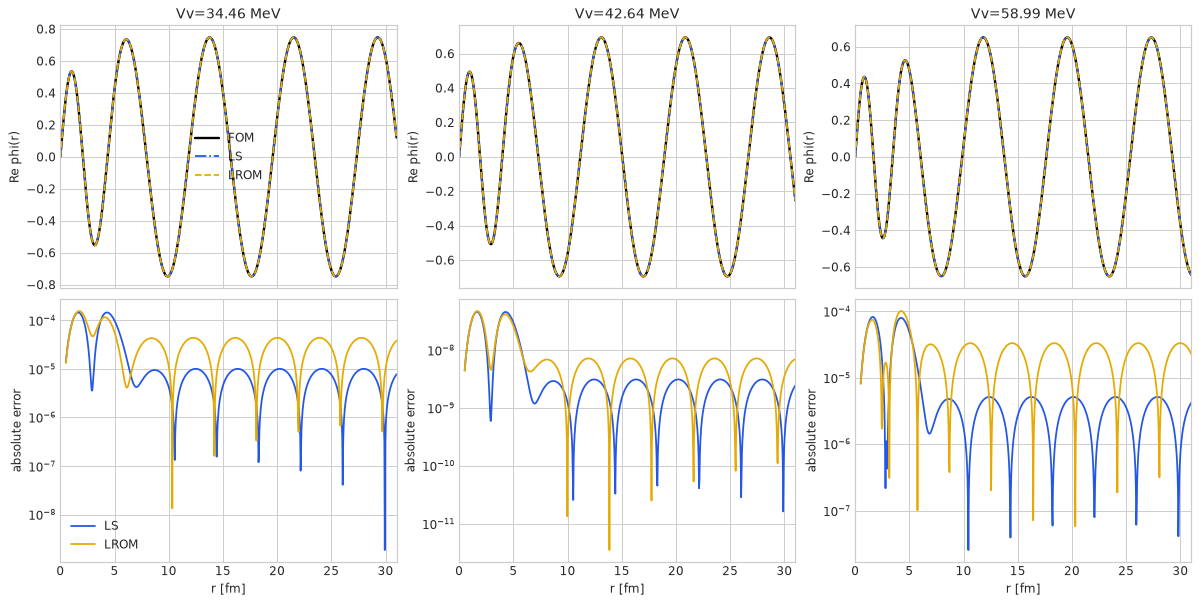

In [8]:
selected_vv = np.array([5, 15, len(test_vv)-6])
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex="col", layout="constrained")
for column, index in enumerate(selected_vv):
    axes[0,column].plot(radius, test_phi_vv[index].real, color="black", lw=2, label="FOM")
    axes[0,column].plot(radius, ls_test_vv[index].real, "-.", color=COLORS["LS"], label="LS")
    axes[0,column].plot(radius, lrom_test_vv[index].real, "--", color=COLORS["LROM"], label="LROM")
    ls_error = np.abs(ls_test_vv[index]-test_phi_vv[index])
    lrom_error = np.abs(lrom_test_vv[index]-test_phi_vv[index])
    axes[1,column].semilogy(radius[radial_error_mask], np.maximum(ls_error[radial_error_mask], ERROR_FLOOR), color=COLORS["LS"], label="LS")
    axes[1,column].semilogy(radius[radial_error_mask], np.maximum(lrom_error[radial_error_mask], ERROR_FLOOR), color=COLORS["LROM"], label="LROM")
    axes[0,column].set(title=f"Vv={test_vv[index,0]:.2f} MeV", ylabel="Re phi(r)")
    axes[1,column].set(xlabel="r [fm]", ylabel="absolute error", xlim=(0,radius[-1]))
axes[0,0].legend(); axes[1,0].legend()
save_figure("N1_vv_held_out")

In [9]:
metrics_vv = pd.DataFrame({
    "method": ["LS", "LROM"],
    "reference": ["Numerov FOM", "Numerov FOM"],
    "training median relative L2": [
        np.median(relative_l2(ls_train_vv, train_phi_vv)[noncentral_train_vv]),
        np.median(relative_l2(lrom_train_vv, train_phi_vv)[noncentral_train_vv]),
    ],
    "testing median relative L2": [
        np.median(relative_l2(ls_test_vv, test_phi_vv)[noncentral_test_vv]),
        np.median(relative_l2(lrom_test_vv, test_phi_vv)[noncentral_test_vv]),
    ],
})
metrics_vv

,method,reference,training median relative L2,testing median relative L2
0,LS,Numerov FOM,2.435013e-08,0.000009
1,LROM,Numerov FOM,2.485518e-08,0.000010


### Training and testing error distributions

[Daniel: Explain split training/testing violins, median markers, and exclusion of the exact central potential.]

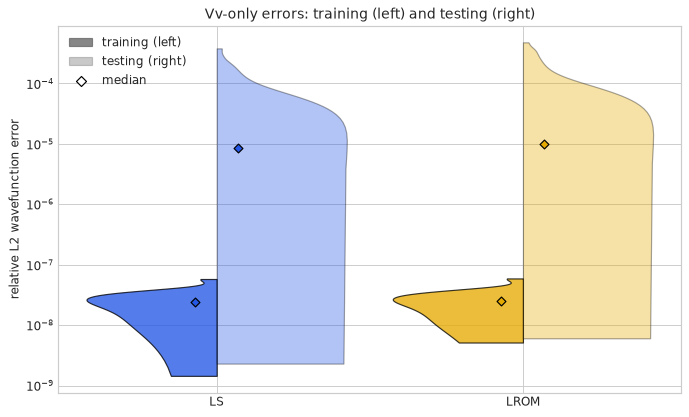

In [10]:
vv_training_errors = {
    "LS": relative_l2(ls_train_vv,train_phi_vv)[noncentral_train_vv],
    "LROM": relative_l2(lrom_train_vv,train_phi_vv)[noncentral_train_vv],
}
vv_testing_errors = {
    "LS": relative_l2(ls_test_vv,test_phi_vv)[noncentral_test_vv],
    "LROM": relative_l2(lrom_test_vv,test_phi_vv)[noncentral_test_vv],
}
methods_vv = ["LS","LROM"]
positions_vv = np.arange(1,len(methods_vv)+1)
fig,ax=plt.subplots(figsize=(8,4.8),layout="constrained")
left=ax.violinplot(
    [vv_training_errors[name] for name in methods_vv],
    positions=positions_vv,widths=.85,showextrema=False,
)
right=ax.violinplot(
    [vv_testing_errors[name] for name in methods_vv],
    positions=positions_vv,widths=.85,showextrema=False,
)
for center,body,name in zip(positions_vv,left["bodies"],methods_vv):
    vertices=body.get_paths()[0].vertices
    vertices[:,0]=np.minimum(vertices[:,0],center)
    body.set_facecolor(COLORS[name]); body.set_edgecolor("black"); body.set_alpha(.78)
    ax.scatter(center-.07,np.median(vv_training_errors[name]),marker="D",s=28,color=COLORS[name],edgecolor="black",zorder=5)
for center,body,name in zip(positions_vv,right["bodies"],methods_vv):
    vertices=body.get_paths()[0].vertices
    vertices[:,0]=np.maximum(vertices[:,0],center)
    body.set_facecolor(COLORS[name]); body.set_edgecolor("black"); body.set_alpha(.35)
    ax.scatter(center+.07,np.median(vv_testing_errors[name]),marker="D",s=28,color=COLORS[name],edgecolor="black",zorder=5)
ax.set_xticks(positions_vv,methods_vv)
ax.set_yscale("log")
ax.set(ylabel="relative L2 wavefunction error",title="Vv-only errors: training (left) and testing (right)")
ax.fill_between([],[],color="0.4",alpha=.78,label="training (left)")
ax.fill_between([],[],color="0.4",alpha=.35,label="testing (right)")
ax.scatter([],[],marker="D",color="white",edgecolor="black",label="median")
ax.legend()
save_figure("N1_vv_error_distributions")

# 2. Simultaneous variation of $(V_v,R_v,a_v)$

[Daniel: Describe the three-parameter training and broader testing Latin-hypercube designs at fixed energy.]

In [11]:
train_ws = latin_hypercube(.90*omega0, 1.10*omega0, 70, SEED)
test_ws = latin_hypercube(
    np.array([.78,.80,.80])*omega0,
    np.array([1.22,1.20,1.20])*omega0,
    81, SEED+1,
)
train_samples_ws = samples_from_rows(train_ws)
test_samples_ws = samples_from_rows(test_ws)
training_data_ws = problem.generate_training_data(train_samples_ws)
testing_data_ws = problem.generate_training_data(test_samples_ws)
train_phi_ws = training_data_ws.wavefunctions[(0, 0.0)]
test_phi_ws = testing_data_ws.wavefunctions[(0, 0.0)]
train_potential_ws = training_data_ws.potentials[(0, 0.0)]
test_potential_ws = testing_data_ws.potentials[(0, 0.0)]
train_physical_potential_ws = np.asarray([
    real_woods_saxon(radius, row) for row in train_ws
])

## 2.1 Potential predictors and the four-dimensional wavefunction basis

[Daniel: Explain selected potential coordinates and the four-dimensional centered wavefunction basis.]

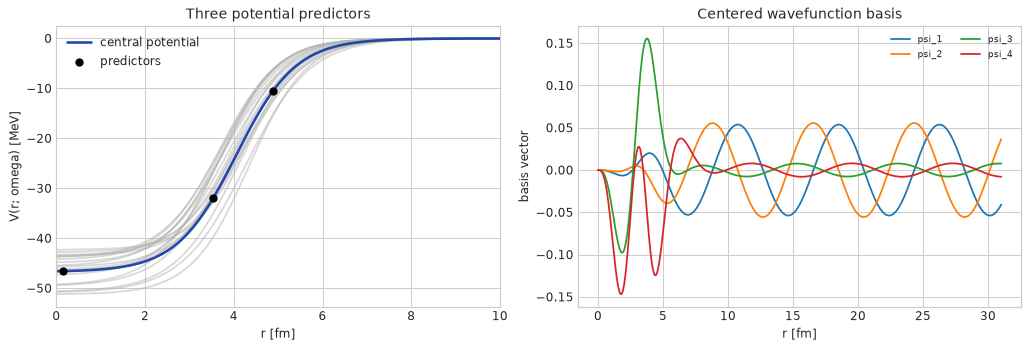

In [12]:
emulator_ws3 = ScatteringLROM(
    problem, BasisConfig(size=BASIS_SIZE), MaxVol(count=3),
).train(training_data_ws)
model_ws3 = emulator_ws3.channel_models[(0, 0.0)].learned
lrom_train_ws3 = np.asarray([
    emulator_ws3.predict(sample).wavefunction((0, 0.0))
    for sample in train_samples_ws
])
lrom_test_ws3 = np.asarray([
    emulator_ws3.predict(sample).wavefunction((0, 0.0))
    for sample in test_samples_ws
])
ls_train_coordinates_ws = model_ws3.basis.project(train_phi_ws)
ls_test_coordinates_ws = model_ws3.basis.project(test_phi_ws)
ls_train_ws = model_ws3.basis.reconstruct(ls_train_coordinates_ws)
ls_test_ws = model_ws3.basis.reconstruct(ls_test_coordinates_ws)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
predictor_r_ws3 = model_ws3.selected_coordinates / system.wave_number
for optical in train_physical_potential_ws[::4]:
    axes[0].plot(radius, optical.real, color="0.7", alpha=.5)
axes[0].plot(radius, potential0.real, color="#2446A8", lw=2.2, label="central potential")
axes[0].scatter(predictor_r_ws3, np.interp(predictor_r_ws3, radius, potential0.real), color="black", zorder=4, label="predictors")
axes[0].set(xlim=(0,10), xlabel="r [fm]", ylabel="V(r; omega) [MeV]", title="Three potential predictors")
axes[0].legend()
for index in range(BASIS_SIZE):
    axes[1].plot(radius, model_ws3.basis.vectors[:,index].real, label=f"psi_{index+1}")
axes[1].set(xlabel="r [fm]", ylabel="basis vector", title="Centered wavefunction basis")
axes[1].legend(ncol=2, fontsize=8)
save_figure("N1_ws_predictors_basis")

## 2.2 Reduced coordinate geometry

[Daniel: Explain fixed-diffuseness manifold slices and training points sampled at independent radii and diffusenesses.]

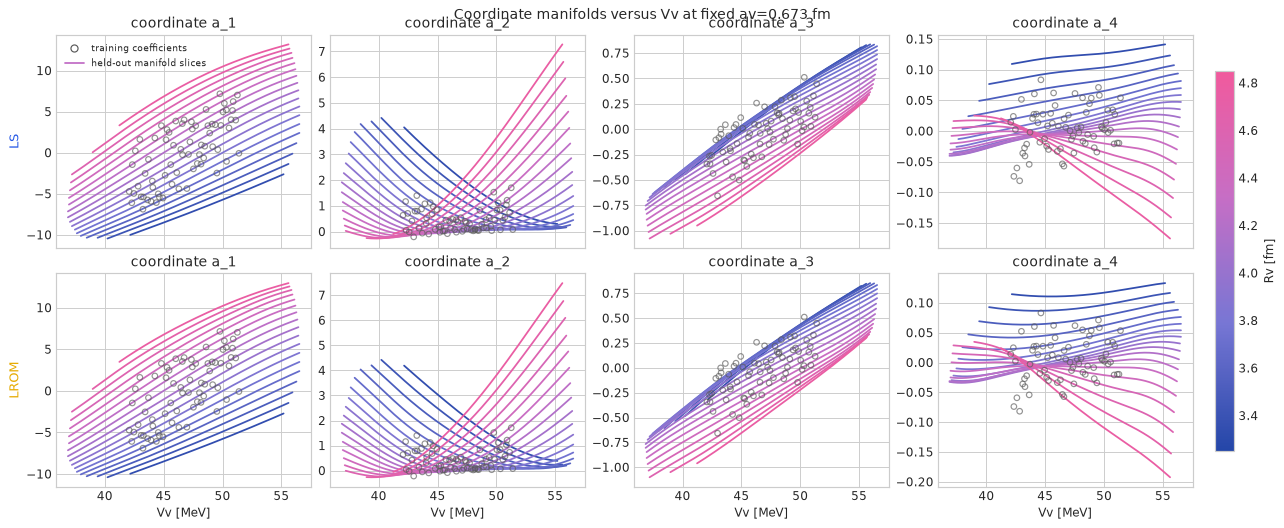

In [13]:
coordinates_ws = {
    "LS": (ls_train_coordinates_ws, ls_test_coordinates_ws, "a", COLORS["LS"]),
    "LROM": (
        np.asarray([emulator_ws3.predict(s).coordinates((0,0.0)) for s in train_samples_ws]),
        np.asarray([emulator_ws3.predict(s).coordinates((0,0.0)) for s in test_samples_ws]),
        "a", COLORS["LROM"],
    ),
}
from scipy.interpolate import LinearNDInterpolator, RBFInterpolator
from matplotlib.lines import Line2D

# Interpolate the held-out coordinates in the complete three-parameter
# space, then inspect one family of slices at the median diffuseness.
parameter_scale = np.maximum(test_ws.std(axis=0), 1.0e-12)
av_fixed = np.median(test_ws[:,2])
vv_grid = np.linspace(test_ws[:,0].min(), test_ws[:,0].max(), 240)
rv_slices = np.linspace(test_ws[:,1].min(), test_ws[:,1].max(), 20)
color_norm = plt.Normalize(rv_slices.min(), rv_slices.max())

fig, axes = plt.subplots(
    2, BASIS_SIZE, figsize=(15, 6), sharex=True,
    layout="constrained",
)
for row_index,(name,(training,testing,symbol,color)) in enumerate(coordinates_ws.items()):
    for column in range(BASIS_SIZE):
        ax = axes[row_index,column]
        values = testing[:,column].real
        smooth = RBFInterpolator(
            test_ws/parameter_scale, values,
            kernel="thin_plate_spline", smoothing=0.05,
        )
        convex_hull = LinearNDInterpolator(test_ws, values)
        for rv in rv_slices:
            query = np.column_stack([
                vv_grid,
                np.full_like(vv_grid,rv),
                np.full_like(vv_grid,av_fixed),
            ])
            inside = ~np.isnan(convex_hull(query))
            curve = np.full_like(vv_grid,np.nan)
            curve[inside] = smooth(query[inside]/parameter_scale)
            ax.plot(
                vv_grid,curve,
                color=PARAMETER_CMAP(color_norm(rv)),lw=1.5,
            )
        ax.scatter(
            train_ws[:,0],training[:,column].real,
            facecolors="none",edgecolors="0.35",s=22,alpha=.65,zorder=3,
        )
        ax.set_title(f"coordinate {symbol}_{column+1}")
        if column==0: ax.set_ylabel(name,color=color,fontsize=11)
        if row_index==1: ax.set_xlabel("Vv [MeV]")
legend_handles = [
    Line2D([0],[0],marker="o",linestyle="none",markerfacecolor="none",markeredgecolor="0.35",label="training coefficients"),
    Line2D([0],[0],color=PARAMETER_CMAP(.65),lw=1.5,label="held-out manifold slices"),
]
axes[0,0].legend(handles=legend_handles,fontsize=8)
scalar_map = plt.cm.ScalarMappable(norm=color_norm,cmap=PARAMETER_CMAP)
fig.colorbar(scalar_map,ax=axes,label="Rv [fm]",shrink=.84,pad=.02)
fig.suptitle(f"Coordinate manifolds versus Vv at fixed av={av_fixed:.3f} fm",y=1.01)
save_figure("N1_ws_coordinates")

## 2.3 Held-out wavefunctions and error distributions

[Daniel: Describe held-out case selection, reconstruction, and absolute error against the full-order solution.]

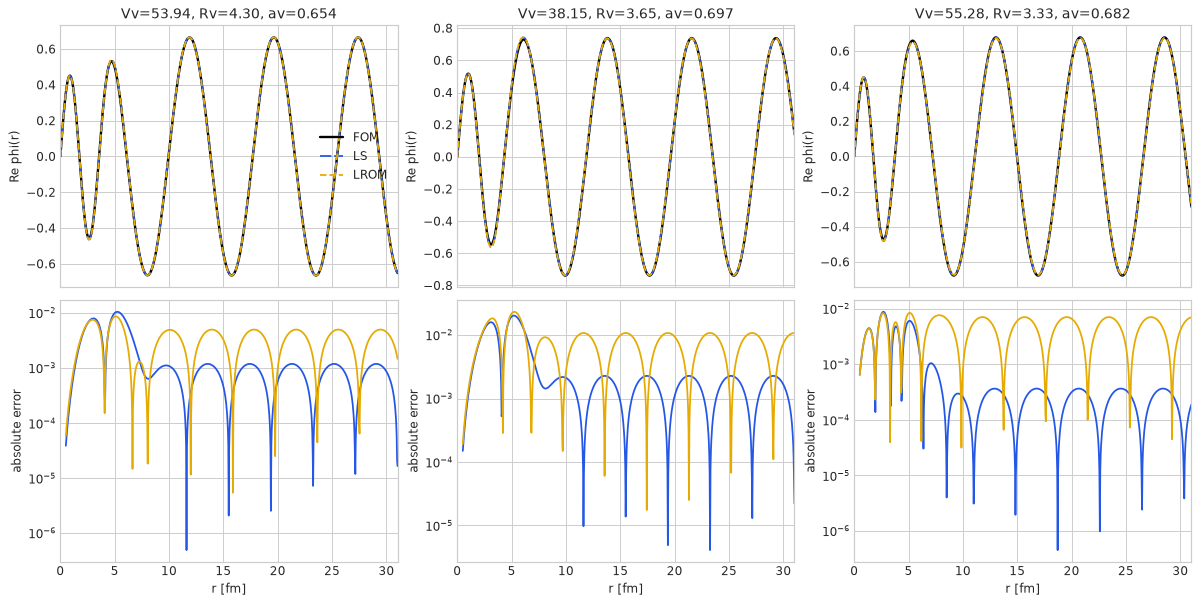

In [14]:
scaled_distance = np.linalg.norm((test_ws-omega0)/(np.array([.22,.20,.20])*omega0), axis=1)
ordered = np.argsort(scaled_distance)
selected_ws = ordered[[20,40,65]]
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex="col", layout="constrained")
for column,index in enumerate(selected_ws):
    axes[0,column].plot(radius,test_phi_ws[index].real,color="black",lw=2,label="FOM")
    axes[0,column].plot(radius,ls_test_ws[index].real,"-.",color=COLORS["LS"],label="LS")
    axes[0,column].plot(radius,lrom_test_ws3[index].real,"--",color=COLORS["LROM"],label="LROM")
    ls_error=np.abs(ls_test_ws[index]-test_phi_ws[index])
    lrom_error=np.abs(lrom_test_ws3[index]-test_phi_ws[index])
    axes[1,column].semilogy(radius[radial_error_mask],np.maximum(ls_error[radial_error_mask],ERROR_FLOOR),color=COLORS["LS"])
    axes[1,column].semilogy(radius[radial_error_mask],np.maximum(lrom_error[radial_error_mask],ERROR_FLOOR),color=COLORS["LROM"])
    axes[0,column].set(title=f"Vv={test_ws[index,0]:.2f}, Rv={test_ws[index,1]:.2f}, av={test_ws[index,2]:.3f}",ylabel="Re phi(r)")
    axes[1,column].set(xlabel="r [fm]",ylabel="absolute error",xlim=(0,radius[-1]))
axes[0,0].legend()
save_figure("N1_ws_held_out")

In [15]:
train_errors_ws3 = {
    "LS": relative_l2(ls_train_ws,train_phi_ws),
    "LROM": relative_l2(lrom_train_ws3,train_phi_ws),
}
test_errors_ws3 = {
    "LS": relative_l2(ls_test_ws,test_phi_ws),
    "LROM": relative_l2(lrom_test_ws3,test_phi_ws),
}
metrics_ws = pd.DataFrame({
    "method": ["LS", "LROM"],
    "basis size": [model_ws3.basis.vectors.shape[1]] * 2,
    "predictor count": [len(model_ws3.selected_coordinates)] * 2,
    "training median relative L2": [np.median(train_errors_ws3[m]) for m in ("LS", "LROM")],
    "testing median relative L2": [np.median(test_errors_ws3[m]) for m in ("LS", "LROM")],
    "testing maximum relative L2": [np.max(test_errors_ws3[m]) for m in ("LS", "LROM")],
})
metrics_ws

,method,basis size,predictor count,training median relative L2,testing median relative L2,testing maximum relative L2
0,LS,4,3,0.001297,0.005479,0.035489
1,LROM,4,3,0.001430,0.010359,0.055487


[Daniel: Compare training and testing error distributions for least-squares projection and learned prediction.]

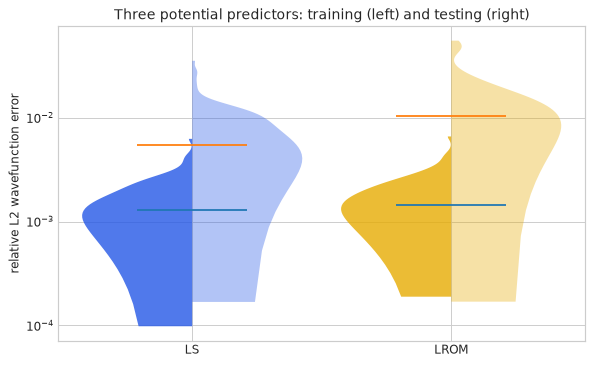

In [16]:
methods = ["LS","LROM"]
positions = np.arange(1,len(methods)+1)
fig,ax=plt.subplots(figsize=(8,4.8))
left=ax.violinplot([train_errors_ws3[m] for m in methods],positions=positions,widths=.85,showmedians=True,showextrema=False)
right=ax.violinplot([test_errors_ws3[m] for m in methods],positions=positions,widths=.85,showmedians=True,showextrema=False)
for center,body,method in zip(positions,left["bodies"],methods):
    body.get_paths()[0].vertices[:,0]=np.minimum(body.get_paths()[0].vertices[:,0],center)
    body.set_facecolor(COLORS[method]); body.set_alpha(.8)
for center,body,method in zip(positions,right["bodies"],methods):
    body.get_paths()[0].vertices[:,0]=np.maximum(body.get_paths()[0].vertices[:,0],center)
    body.set_facecolor(COLORS[method]); body.set_alpha(.35)
ax.set_xticks(positions,methods); ax.set_yscale("log")
ax.set(ylabel="relative L2 wavefunction error",title="Three potential predictors: training (left) and testing (right)")
save_figure("N1_ws_error_distributions")

In [17]:
_matplotlib_config.cleanup()